In [14]:
import pandas as pd
import matplotlib.pyplot as plt

In [15]:
df = pd.read_csv("StudentsPerformance.csv")
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [17]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [18]:
df["average"]=df[["math score","reading score","writing score"]].mean(axis=1)
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,average
0,female,group B,bachelor's degree,standard,none,72,72,74,72.666667
1,female,group C,some college,standard,completed,69,90,88,82.333333
2,female,group B,master's degree,standard,none,90,95,93,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,49.333333
4,male,group C,some college,standard,none,76,78,75,76.333333


In [19]:
df.groupby("gender")[["math score","reading score","writing score","average"]].mean()

,math score,reading score,writing score,average
gender,,,,
female,63.633205,72.608108,72.467181,69.569498
male,68.728216,65.473029,63.311203,65.837483


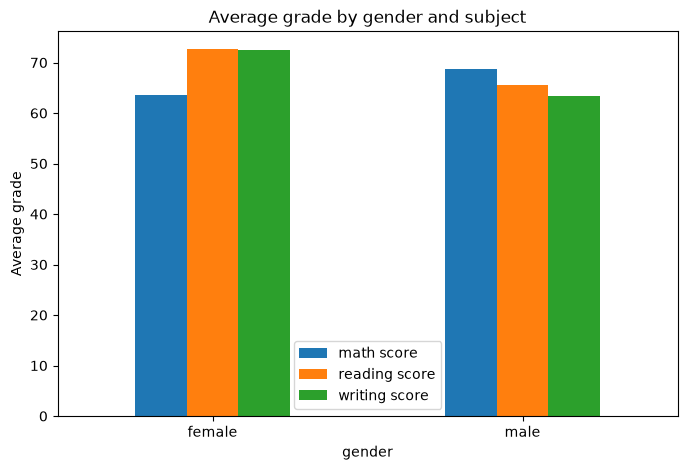

In [20]:
gender_means = df.groupby("gender")[["math score", "reading score", "writing score"]].mean()

gender_means.plot(kind="bar", figsize=(8, 5))
plt.title("Average grade by gender and subject")
plt.ylabel("Average grade")
plt.xlabel("gender")
plt.xticks(rotation=0)
plt.show()

### Συμπέρασμα 1: Επιδόσεις ανά φύλο
Οι γυναικες έχουν καλύτερο συνολικό μέσο όρο εναντι των αντρων.
Οι άντρες υπερέχουν στο math score	, ενώ οι γυναίκες στο reading score και στο writing score

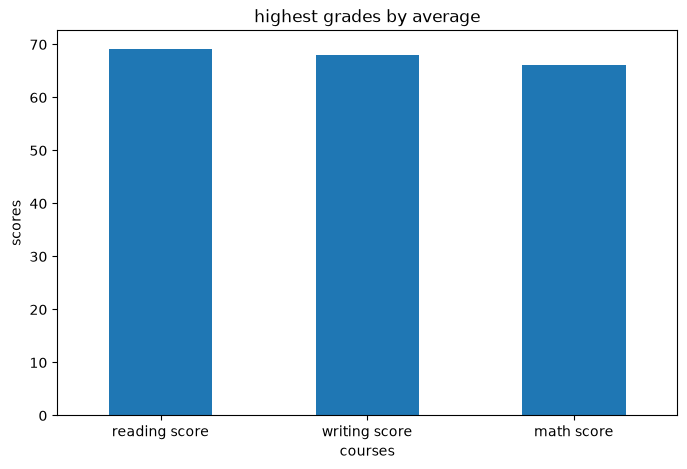

In [21]:
highest_grades=df.filter(regex="score$").mean()
highest_grades=highest_grades.sort_values(ascending=False)
highest_grades.plot(kind="bar",figsize=(8,5))
plt.title("highest grades by average")
plt.ylabel("scores")
plt.xlabel("courses")
plt.xticks(rotation=0)
plt.show()


### Συμπερασμα 2:
Το μεγαλυτερο average score το εχει το reading μετα ακολουθει writing και τελος math

In [22]:
df["test preparation course"].value_counts()

test preparation course
none         642
completed    358
Name: count, dtype: int64

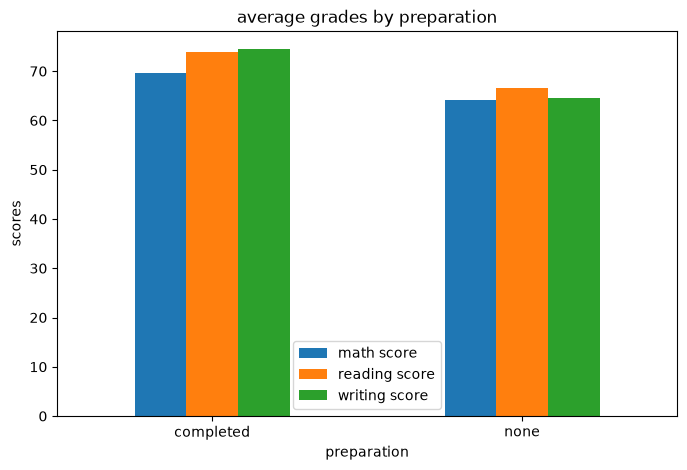

In [23]:
preparation_means=df.groupby("test preparation course")[["math score", "reading score", "writing score"]].mean()
preparation_means.plot(kind="bar",figsize=(8,5))
plt.title("average grades by preparation")
plt.ylabel("scores")
plt.xlabel("preparation")
plt.xticks(rotation=0)
plt.show()

### Συμπέρασμα 3: Επίδραση του test preparation
Οι μαθητές που ολοκλήρωσαν το course έχουν καλύτερους βαθμούς και στα τρία μαθήματα από όσους δεν το έκαναν.
Η μεγαλύτερη διαφορά είναι στο writing score και η μικρότερη στο math score 
Προσοχή: το dataset δείχνει συσχέτιση και όχι αιτία. Πιθανόν οι πιο προσηλωμένοι μαθητές να επιλέγουν και την προετοιμασία.

In [24]:
(df["math score"] > 80).mean() * 100


np.float64(17.599999999999998)

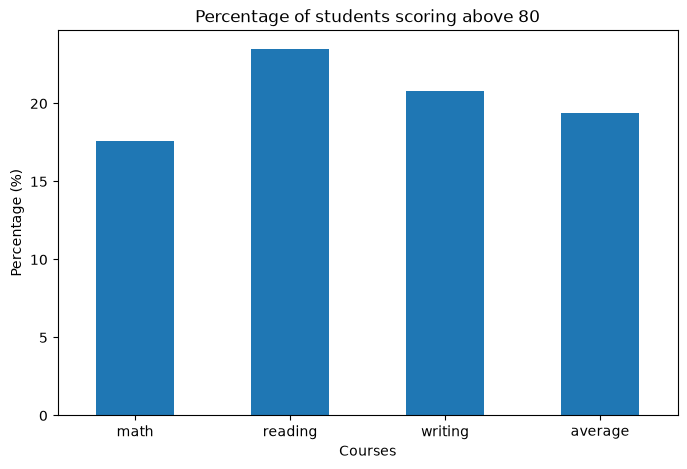

In [25]:
grades_over_80={
    "math": (df["math score"] > 80).mean() * 100,
    "reading": (df["reading score"] > 80).mean() * 100,
    "writing": (df["writing score"] > 80).mean() * 100,
    "average": (df["average"] > 80).mean() * 100
}

grades_Series=pd.Series(grades_over_80)

grades_Series.plot(kind="bar",figsize=(8,5))
plt.title("Percentage of students scoring above 80")
plt.ylabel("Percentage (%)")
plt.xlabel("Courses")
plt.xticks(rotation=0)
plt.show()




### Συμπέρασμα 4: Μαθητές με βαθμό πάνω από 80
Το reading έχει το μεγαλύτερο ποσοστό μαθητών πάνω από 80 (23,5%), ακολουθεί το writing (20,8%) και τελευταίο το math (17,6%).
Ο γενικός μέσος όρος (19,4%) βρίσκεται ανάμεσα, γιατί συνδυάζει και τα τρία μαθήματα.
Συνολικά, μόνο περίπου ένας στους 5 μαθητές ξεπερνά το 80.

In [26]:
df.groupby("lunch")["average"].mean().sort_values()

lunch
free/reduced    62.199061
standard        70.837209
Name: average, dtype: float64

In [27]:
df.groupby("race/ethnicity")["average"].mean().sort_values()

race/ethnicity
group A    62.992509
group B    65.468421
group C    67.131661
group D    69.179389
group E    72.752381
Name: average, dtype: float64

In [28]:
df.groupby("parental level of education")["average"].mean().sort_values()

parental level of education
high school           63.096939
some high school      65.108007
some college          68.476401
associate's degree    69.569069
bachelor's degree     71.923729
master's degree       73.598870
Name: average, dtype: float64

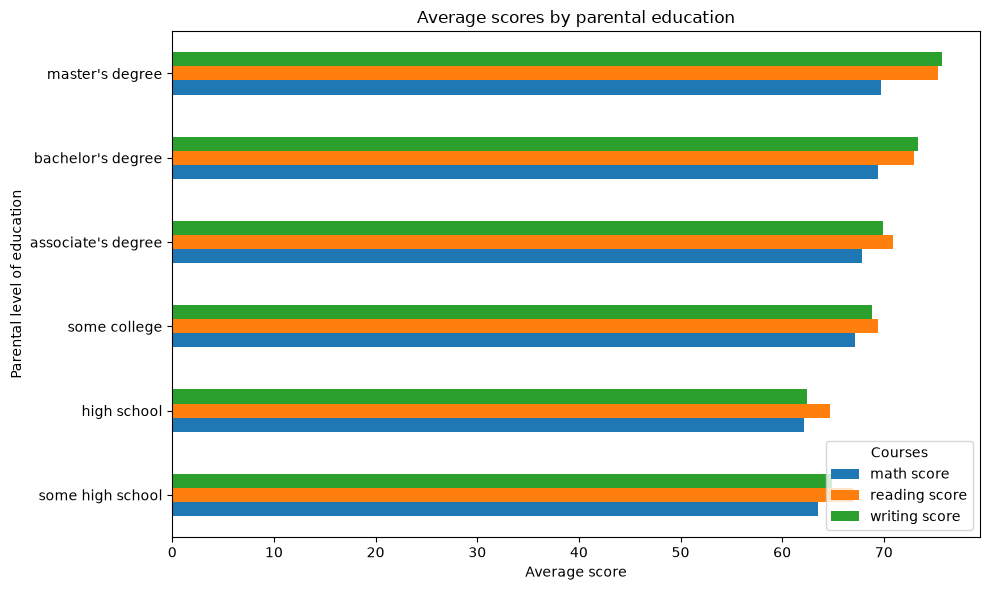

In [29]:
parental_avg=df.groupby("parental level of education")[["math score", "reading score", "writing score"]].mean()
order = ["some high school", "high school", "some college",
         "associate's degree", "bachelor's degree", "master's degree"]
parental_avg = parental_avg.reindex(order)
parental_avg.plot(kind="barh",figsize=(10,6))
plt.title("Average scores by parental education")
plt.xlabel("Average score")
plt.ylabel("Parental level of education")
plt.legend(title="Courses")
plt.tight_layout()
plt.show()


### Συμπέρασμα 5: Ομάδες με τις χαμηλότερες επιδόσεις
Η χαμηλότερη επίδοση εμφανίζεται στους μαθητές με γονείς που έχουν hihg school (μέσος όρος 63,09) και σε όσους έχουν lunch τύπου ... (...).
Στο race/ethnicity η χαμηλότερη ομάδα είναι η group A (62.992509), ενώ η μεγαλύτερη διαφορά ανάμεσα στην καλύτερη και τη χειρότερη ομάδα βρίσκεται στην parental level of education (10,501 μονάδες).
Ο συνδυασμός lunch free/reduced και test preparation none έχει τον χαμηλότερο μέσο όρο (58.949405), ενώ ο καλύτερος είναι ο lunch standard και test preparation completed (75.505140).
Ο μέσος όρος ανεβαίνει σχεδόν σταθερά με το μορφωτικό επίπεδο των γονέων. Εξαίρεση είναι το "some high school", που έχει λίγο υψηλότερο μέσο όρο από το "high school".

In [30]:
df.groupby(["lunch","test preparation course"])["average"].mean().sort_values()

lunch         test preparation course
free/reduced  none                       58.949405
              completed                  67.755725
standard      none                       68.302233
              completed                  75.505140
Name: average, dtype: float64

In [31]:
df.loc[df["average"]<40]

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,average
17,female,group B,some high school,free/reduced,none,18,32,28,26.000000
55,female,group C,high school,free/reduced,none,33,41,43,39.000000
59,female,group C,some high school,free/reduced,none,0,17,10,9.000000
61,male,group A,some high school,free/reduced,none,39,39,34,37.333333
66,male,group D,some high school,free/reduced,none,45,37,37,39.666667
76,male,group E,some high school,standard,none,30,26,22,26.000000
84,male,group D,high school,free/reduced,none,42,39,34,38.333333
91,male,group C,high school,free/reduced,none,27,34,36,32.333333
145,female,group C,some college,free/reduced,none,22,39,33,31.333333
211,male,group C,some college,free/reduced,none,35,28,27,30.000000


In [32]:
len(df.loc[df["average"]<40])

30

In [33]:
df.iloc[:5,:3]

,gender,race/ethnicity,parental level of education
0,female,group B,bachelor's degree
1,female,group C,some college
2,female,group B,master's degree
3,male,group A,associate's degree
4,male,group C,some college


In [34]:
df.groupby("gender")["average"].count()

gender
female    518
male      482
Name: average, dtype: int64

## Συμπεράσματα

1. **Φύλο:** Οι γυναικες έχουν καλύτερο συνολικό μέσο όρο, με τους άντρες να υπερέχουν στο math και τις γυναίκες στο reading και στο writing
2. **Μαθήματα:** Το reading έχει τις καλύτερες επιδόσεις, ενώ το math τις χαμηλότερες.
3. **Test preparation:** Οι μαθητές που ολοκλήρωσαν το course έχουν καλύτερους βαθμούς και στα τρία μαθήματα, με τη μεγαλύτερη διαφορά στο writing, αλλά πρόκειται για συσχέτιση και όχι αιτία.
4. **Βαθμοί πάνω από 80:** Μόνο το 19,4% των μαθητών ξεπερνά το 80 στον γενικό μέσο όρο, με το reading να έχει το μεγαλύτερο ποσοστό (23,5%).
5. **Χαμηλότερες επιδόσεις:** Η χαμηλότερη ομάδα είναι οι μαθητές με free/reduced lunch χωρίς test preparation, ενώ το μορφωτικό επίπεδο των γονέων είναι ο παράγοντας με τη μεγαλύτερη διαφορά (10,501 μονάδες).